# 06 — Đánh giá khả năng phát hiện tấn công mới

> **Đầu việc 06/6** trong pipeline phát hiện xâm nhập NSL-KDD.

**Mục tiêu**
- Xác định 17 loại tấn công chỉ xuất hiện trong test.
- Đo recall riêng trên nhóm novel và nhóm đã biết.
- So sánh unsupervised vs supervised trên tấn công chưa từng thấy.

Đây là kết quả cốt lõi của đề tài: mô hình nào tổng quát hóa tốt hơn với signature mới.

## 0. Môi trường

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nids.config import (CATEGORICAL, DATA_PROCESSED, FEATURES, RANDOM_STATE,
                         REPORTS, FAMILY_ORDER)
from nids.data import load_train_test, to_binary_label, to_family_label, novel_attack_types

pd.set_option("display.float_format", lambda x: f"{x:.4f}")
np.random.seed(RANDOM_STATE)
print("Project root:", PROJECT_ROOT)
print("RANDOM_STATE =", RANDOM_STATE)

Project root: /mnt/Data/ptit/Network_Intrusion&Cyber_Attack_Detection
RANDOM_STATE = 36


## 1. Xác định tấn công mới

Test có 37 loại tấn công, train có 22 loại → 17 loại novel.

In [2]:
# 1) Xác định tấn công mới: loai chi co trong test, chua tung thay o train
train, test = load_train_test()
novel = novel_attack_types(train, test)
print(f"số loại tấn công moi: {len(novel)}")
print(novel)

số loại tấn công moi: 17
['apache2', 'httptunnel', 'mailbomb', 'mscan', 'named', 'processtable', 'ps', 'saint', 'sendmail', 'snmpgetattack', 'snmpguess', 'sqlattack', 'udpstorm', 'worm', 'xlock', 'xsnoop', 'xterm']


## 2. Chia test thành known vs novel

- Known: tấn công đã thấy khi train + Normal.
- Novel: chỉ các dòng thuộc 17 loại mới.

In [3]:
# 2) Chia test thành known và novel
novel_mask = test["label"].isin(novel).to_numpy()
known_mask = ~novel_mask
print("novel rows:", int(novel_mask.sum()), "| known rows:", int(known_mask.sum()))
print("tỉ lệ novel trong so attack test:",
      round(float(novel_mask.sum() / max((test["label"] != "normal").sum(), 1)), 4))

novel rows: 3750 | known rows: 18794
tỉ lệ novel trong so attack test: 0.2922


## 3. Recall trên novel

Tính recall tổng và theo từng loại/họ. Đừng gộp chung với known vì sẽ che mất khác biệt.

In [4]:
# 3) Nạp prediction cua tung mô hình (supervised can fit lai, unsup nap tu file)
X_train = np.load(DATA_PROCESSED / "X_train.npy")
X_test = np.load(DATA_PROCESSED / "X_test.npy")
y_train_binary = np.load(DATA_PROCESSED / "y_train_binary.npy", allow_pickle=True)

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

logreg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
xgb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    subsample=0.9, colsample_bytree=0.9,
                    random_state=RANDOM_STATE, n_jobs=-1, tree_method="hist")
for m in (logreg, rf, xgb):
    m.fit(X_train, y_train_binary)

preds = {
    "LogReg (supervised)": logreg.predict(X_test),
    "RandomForest (supervised)": rf.predict(X_test),
    "XGBoost (supervised)": xgb.predict(X_test),
    "Euclidean (unsupervised)": np.load(DATA_PROCESSED / "y_pred_euclidean.npy", allow_pickle=True),
    "Mahalanobis (unsupervised)": np.load(DATA_PROCESSED / "y_pred_mahalanobis.npy", allow_pickle=True),
}
print("đã có prediction cho", len(preds), "mô hình")

đã có prediction cho 5 mô hình


## 4. So sánh unsupervised vs supervised

In [5]:
# 4) Recall trên novel, chia theo họ va theo từng tên tấn công
from nids.data import to_family_label

y_test_family = to_family_label(test).to_numpy()
test_labels = test["label"].to_numpy()

def recall(mask, pred):
    return round(float(pred[mask].mean()), 4) if mask.sum() else np.nan

# 4a) Recall theo ho tren nhom NOVEL
rows = {}
for name, pred in preds.items():
    vals = {}
    for fam in ["DoS", "Probe", "R2L", "U2R"]:
        mask = novel_mask & (y_test_family == fam)
        vals[fam] = recall(mask, pred)
    vals["novel tổng"] = recall(novel_mask, pred)
    vals["known attack"] = recall(known_mask & (test_labels != "normal"), pred)
    rows[name] = vals
novel_by_family = pd.DataFrame(rows).T
print(novel_by_family.to_string())

# 4b) Recall theo từng tên tấn công moi (17 loai)
rows = {}
for name, pred in preds.items():
    rows[name] = {atk: recall(test_labels == atk, pred) for atk in novel}
per_attack = pd.DataFrame(rows)
print(per_attack.to_string())

                              DoS  Probe    R2L    U2R  novel tổng  known attack
LogReg (supervised)        0.4252 0.5924 0.0102 0.1333      0.4056        0.7131
RandomForest (supervised)  0.0780 0.5802 0.0087 0.2000      0.2424        0.7702
XGBoost (supervised)       0.3566 0.4593 0.0102 0.2333      0.3283        0.7727
Euclidean (unsupervised)   0.0977 0.7985 0.0656 0.5333      0.3411        0.4741
Mahalanobis (unsupervised) 0.8016 0.8973 0.2420 0.7333      0.7323        0.8752
               LogReg (supervised)  RandomForest (supervised)  XGBoost (supervised)  Euclidean (unsupervised)  Mahalanobis (unsupervised)
apache2                     0.9891                     0.1723                0.6174                    0.0624                      0.9973
httptunnel                  0.0150                     0.0226                0.0150                    0.1278                      0.9925
mailbomb                    0.0000                     0.0000                0.0000                 

## 5. Kết luận

Trả lời: phương pháp nào phát hiện tấn công mới tốt hơn, và đánh đổi là gì?

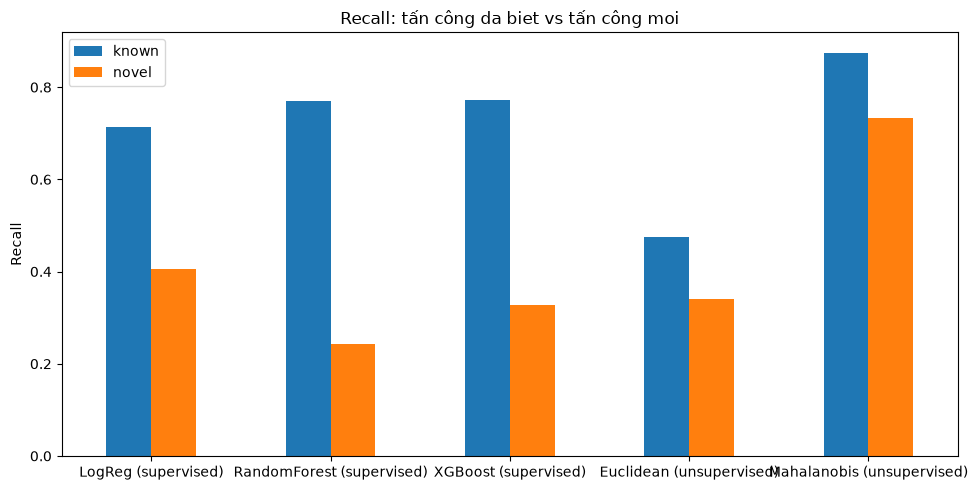

đã lưu reports/figures/06_novel_recall.png
                              DoS  Probe    R2L    U2R  novel tổng  known attack
LogReg (supervised)        0.4252 0.5924 0.0102 0.1333      0.4056        0.7131
RandomForest (supervised)  0.0780 0.5802 0.0087 0.2000      0.2424        0.7702
XGBoost (supervised)       0.3566 0.4593 0.0102 0.2333      0.3283        0.7727
Euclidean (unsupervised)   0.0977 0.7985 0.0656 0.5333      0.3411        0.4741
Mahalanobis (unsupervised) 0.8016 0.8973 0.2420 0.7333      0.7323        0.8752


In [6]:
# 5) Vẽ bar chart so sánh known vs novel
import matplotlib.pyplot as plt

plot_df = novel_by_family[["known attack", "novel tổng"]].copy()
plot_df.columns = ["known", "novel"]
ax = plot_df.plot(kind="bar", figsize=(10, 5), rot=0)
ax.set_ylabel("Recall"); ax.set_title("Recall: tấn công da biet vs tấn công moi")
fig = ax.get_figure(); fig.tight_layout()
fig.savefig(REPORTS / "figures" / "06_novel_recall.png", dpi=130)
plt.show()
print("đã lưu reports/figures/06_novel_recall.png")
print(novel_by_family.to_string())

**Kết quả chính (test, recall trên tấn công mới):**

- **Mahalanobis (unsupervised)** tổng quát tốt nhất: recall novel **0.73** (known attack 0.88),
  nhanh hơn hẳn LogReg (0.41), RF (0.24) và XGBoost (0.33). Trên họ hiếm: U2R **0.73**
  (LogReg 0.13, XGB 0.23), R2L **0.24** (LogReg/XGB ~0.01).
- Một số novel bị bắt trọn: `saint` ~0.64–0.99 mọi mô hình, `sqlattack` và `xterm` Mahalanobis
  đều **1.00 / 0.77**. Ngược lại `worm`, `snmpgetattack`, `snmpguess`, `mailbomb` gần như
  bị bỏ sót bởi tất cả — đây là giới hạn của cả hai hướng.
- **Đánh đổi:** unsupervised chi phí ít dữ liệu (chỉ học Normal) và bắt novel tốt hơn,
  nhưng báo nhầm cao hơn (FPR ~7.4% so với RF/XGB ~2.8%). Supervised chính xác hơn trên
  tấn công đã biết nhưng sụp đổ trên R2L novel (RF/XGB chỉ ~0.01).

=> Trong phạm vi đề tài, **anomaly detection bằng Mahalanobis** là đáp án cho mục tiêu
phát hiện tấn công mới; supervised đóng vai trò baseline để đo cái giá phải trả (FPR cao).


## Checklist hoàn thành

- [x] Đã xác định đúng 17 loại novel.
- [x] Đã tách known/novel và báo cáo riêng.
- [x] Có recall theo từng loại tấn công mới.
- [x] Có so sánh trực tiếp unsupervised vs supervised.
- [x] Có kết luận trả lời mục tiêu đề tài.